# PROG8431 — Solutions to Highway Congestion
## Workshop C+D: Data Transformation and Linear Regression

**Group members:** Jasper Lim (9117038), John Buni (9115726), Eche Oji (9078881)  
**GitHub repository:** https://github.com/JohnBuni/Data-Analysis-Project-Group4.git

**Purpose.** Transform and augment the 2024 Ontario provincial highway segment data with the 1988–2024 traffic-volume dataset. Predict 2024 Annual Average Daily Traffic (AADT), compare simple linear regression models, and select an interpretable final multiple linear regression model.

**Secondary data source:** https://www.library.mto.gov.on.ca/SydneyPLUS/TechPubs/Portal/tp/tvSplash.aspx

## 1. Data setup and exploration

The Excel file is stored in `data` beside this notebook. We inspect the structure and missing values before cleaning and augmentation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline

df = pd.read_excel("./data/Provincial Highways Traffic Volumes 2024 AADT Only.xlsx")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2712, 5)


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT
0,QEW,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,CENTRAL AV IC,0.230,13400.0
1,QEW,CENTRAL AV IC,CONCESSION RD IC-1,0.933,19100.0
2,QEW,CONCESSION RD IC-1,THOMPSON RD IC-2,1.045,18300.0
3,QEW,THOMPSON RD IC-2,GILMORE RD IC-5,2.450,22600.0
4,QEW,GILMORE RD IC-5,BOWEN RD IC-7,2.059,26300.0


In [2]:
print("Data types and non-null counts:")
df.info()
print("\nMissing values:")
print(df.isna().sum())
print("\nDescriptive statistics:")
display(df[["Distance (KM)", "2024 AADT"]].describe().round(2))

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2712 entries, 0 to 2711
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Highway                    2408 non-null   object 
 1   Location Description From  2408 non-null   object 
 2   Location Description To    2408 non-null   object 
 3   Distance (KM)              2101 non-null   float64
 4   2024 AADT                  1810 non-null   float64
dtypes: float64(2), object(3)
memory usage: 106.1+ KB

Missing values:
Highway                      304
Location Description From    304
Location Description To      304
Distance (KM)                611
2024 AADT                    902
dtype: int64

Descriptive statistics:


,Distance (KM),2024 AADT
count,2101.00,1810.00
mean,9.12,31808.32
std,13.86,66712.33
min,0.10,10.00
25%,2.07,2012.50
50%,4.74,7350.00
75%,10.20,23500.00
max,178.60,511400.00


### Augmentation source and rationale

The additional source is **Traffic_Volumes_1988-2024.csv**, containing historical AADT and related traffic measurements by highway location and year. We match records by highway number and a normalized location-description key, clean numeric fields, and pivot historical observations into one row per matched 2024 highway segment. The derived features include historical mean, median, minimum, maximum, standard deviation, coefficient of variation, trend slope, 1988 and 2024 AADT, and recent growth. Categorical highway, region, pattern, and direction fields are converted to numeric indicator variables.

In [3]:
historical = pd.read_csv("./data/Traffic_Volumes_1988-2024.csv", encoding="cp1252", dtype=str)

numeric_historical = [
    "Year", "LHRS", "Offset", "Length", "Conn. Link Length", "PDCS #",
    "DHV %", "Design Hr. Dir Split %", "AADT", "SADT", "SAWDT", "WADT",
    "Truck %", "Truck AADTT"
]
for column in numeric_historical:
    historical[column] = pd.to_numeric(historical[column].str.replace(",", "", regex=False), errors="coerce")

def normalize_location(value):
    if pd.isna(value):
        return ""
    value = re.sub(r"[^A-Z0-9 ]", " ", str(value).upper())
    return re.sub(r"\s+", " ", value).strip()

def highway_key(value):
    value = str(value).strip().upper()
    return "1" if value == "QEW" else value

df["Highway_Key"] = df["Highway"].map(highway_key)
df["Location_Key"] = df["Location Description From"].map(normalize_location)
df["Merge_Key"] = df["Highway_Key"] + "|" + df["Location_Key"]

historical["Highway_Key"] = historical["Hwy No"].map(lambda value: str(value).strip())
historical["Location_Key"] = historical["Description"].map(normalize_location)
historical["Merge_Key"] = historical["Highway_Key"] + "|" + historical["Location_Key"]
historical = historical.replace({"N/A": np.nan})
historical = historical.sort_values(["Merge_Key", "Year"]).drop_duplicates(["Merge_Key", "Year"], keep="first")

pivot_aadt = historical.pivot(index="Merge_Key", columns="Year", values="AADT")
pivot_aadt.columns = [f"AADT_{int(year)}" for year in pivot_aadt.columns]
historical_features = pivot_aadt.copy()

aadt_values = historical.loc[historical["Year"] < 2024, ["Merge_Key", "Year", "AADT"]].dropna(subset=["AADT"])
aggregates = aadt_values.groupby("Merge_Key").agg(
    Historical_AADT_mean=("AADT", "mean"),
    Historical_AADT_median=("AADT", "median"),
    Historical_AADT_min=("AADT", "min"),
    Historical_AADT_max=("AADT", "max"),
    Historical_AADT_std=("AADT", "std"),
    Historical_observation_count=("AADT", "count")
)
aggregates["Historical_AADT_range"] = aggregates["Historical_AADT_max"] - aggregates["Historical_AADT_min"]
aggregates["Historical_AADT_cv"] = aggregates["Historical_AADT_std"] / aggregates["Historical_AADT_mean"]

def trend_slope(group):
    group = group.sort_values("Year")
    if len(group) < 2 or group["Year"].nunique() < 2:
        return np.nan
    return np.polyfit(group["Year"] - group["Year"].min(), group["AADT"], 1)[0]

aggregates["Historical_AADT_slope"] = aadt_values.groupby("Merge_Key").apply(trend_slope, include_groups=False)

def recent_growth(group):
    group = group[group["Year"] >= 2015].sort_values("Year")
    if len(group) < 2:
        return np.nan
    first, last = group.iloc[0]["AADT"], group.iloc[-1]["AADT"]
    return np.nan if pd.isna(first) or first == 0 else (last - first) / first

aggregates["Historical_recent_growth"] = aadt_values.groupby("Merge_Key").apply(recent_growth, include_groups=False)

for column in ["SADT", "SAWDT", "WADT", "Truck %", "Truck AADTT", "DHV %", "Design Hr. Dir Split %"]:
    if column in historical:
        clean_name = column.replace(" ", "_").replace("%", "pct")
        aggregates[f"Historical_{clean_name}_mean"] = historical.groupby("Merge_Key")[column].mean()

context = historical.groupby("Merge_Key").agg(
    Historical_Length=("Length", "median"),
    Historical_Highway_Type=("Hwy. Type", lambda values: values.mode().iloc[0] if not values.mode().empty else np.nan),
    Historical_Region=("Region", lambda values: values.mode().iloc[0] if not values.mode().empty else np.nan),
    Historical_Pattern=("Pattern Type", lambda values: values.mode().iloc[0] if not values.mode().empty else np.nan),
    Historical_Direction=("Design Hr. Dir Split Higher Volume Direction", lambda values: values.mode().iloc[0] if not values.mode().empty else np.nan)
)

augmented = df.merge(historical_features, left_on="Merge_Key", right_index=True, how="left")
augmented = augmented.merge(aggregates, left_on="Merge_Key", right_index=True, how="left")
augmented = augmented.merge(context, left_on="Merge_Key", right_index=True, how="left")
augmented["Year"] = 2024
augmented["Distance_log"] = np.log1p(augmented["Distance (KM)"])
augmented["AADT_log"] = np.log1p(augmented["2024 AADT"])
augmented["Historical_AADT_1988"] = augmented.get("AADT_1988")
augmented["Historical_AADT_2024"] = augmented.get("AADT_2024")
augmented["Historical_growth_since_1988"] = (
    (augmented["Historical_AADT_2024"] - augmented["Historical_AADT_1988"])
    / augmented["Historical_AADT_1988"].replace(0, np.nan)
)

categorical = ["Highway", "Historical_Highway_Type", "Historical_Region", "Historical_Pattern", "Historical_Direction"]
augmented = pd.get_dummies(augmented, columns=categorical, prefix=categorical, dummy_na=False, dtype=int)

study = augmented.dropna(subset=["2024 AADT", "Distance (KM)"]).copy()
study = study[(study["2024 AADT"] > 0) & (study["Distance (KM)"] > 0)].copy()
print("Historical merge coverage:", round(augmented["Historical_observation_count"].notna().mean(), 3))
print("Study shape:", study.shape)
print("Numeric model columns:", len(study.select_dtypes(include=[np.number]).columns))
display(study[["Highway_Key", "Location Description From", "Distance (KM)", "2024 AADT", "Historical_AADT_mean", "Historical_AADT_slope"]].head())

Historical merge coverage: 0.656
Study shape: (1810, 401)
Numeric model columns: 396


,Highway_Key,Location Description From,Distance (KM),2024 AADT,Historical_AADT_mean,Historical_AADT_slope
0,1,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,0.230,13400.0,17635.714286,-345.869741
1,1,CENTRAL AV IC,0.933,19100.0,17568.571429,129.634129
2,1,CONCESSION RD IC-1,1.045,18300.0,17068.571429,162.588197
3,1,THOMPSON RD IC-2,2.450,22600.0,17894.285714,281.490740
4,1,GILMORE RD IC-5,2.059,26300.0,20545.714286,336.126817


### Train/test split rationale

We use a random 80/20 split with `random_state=42` so coefficients are learned on most segments and validated on unseen segments. We compare AADT and distance distributions, plus historical predictors, to check whether the sets are comparable.

Training rows: 1448 Testing rows: 362


,Training mean,Testing mean,Training std,Testing std
Distance (KM),9.00,9.71,12.25,13.31
2024 AADT,32313.91,29785.97,67356.88,64119.89
Historical_AADT_mean,25621.98,23240.79,53452.83,49642.08
Historical_AADT_slope,436.08,381.52,997.45,902.04
Historical_AADT_cv,0.17,0.17,0.11,0.11


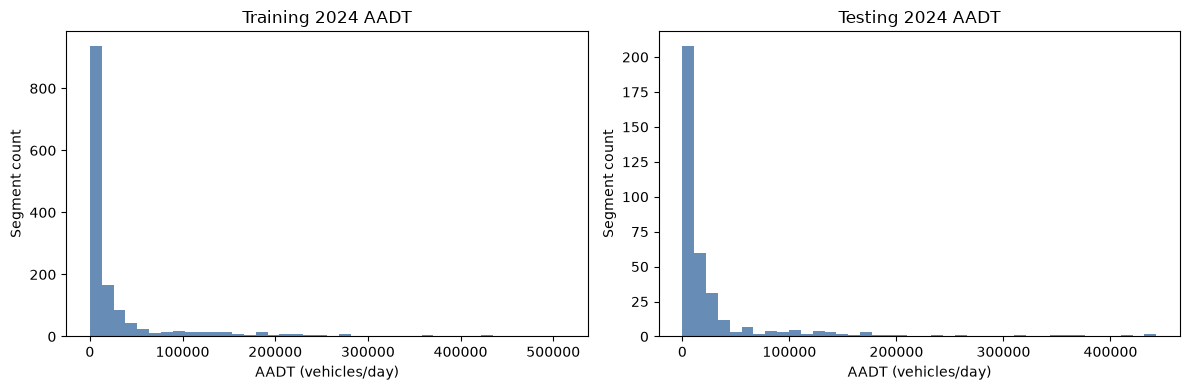

In [4]:
train_set, test_set = train_test_split(study, test_size=0.20, random_state=42)

comparison_columns = ["Distance (KM)", "2024 AADT", "Historical_AADT_mean", "Historical_AADT_slope", "Historical_AADT_cv"]
comparison = pd.concat([
    train_set[comparison_columns].mean().rename("Training mean"),
    test_set[comparison_columns].mean().rename("Testing mean"),
    train_set[comparison_columns].std().rename("Training std"),
    test_set[comparison_columns].std().rename("Testing std")
], axis=1)
print("Training rows:", len(train_set), "Testing rows:", len(test_set))
display(comparison.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, data) in zip(axes, [("Training", train_set), ("Testing", test_set)]):
    ax.hist(data["2024 AADT"].dropna(), bins=40, color="#4C78A8", alpha=0.85)
    ax.set_title(f"{name} 2024 AADT")
    ax.set_xlabel("AADT (vehicles/day)")
    ax.set_ylabel("Segment count")
plt.tight_layout()
plt.show()

### Dependent variable and simple-model comparison

The dependent variable is **2024 AADT**. The first model uses segment **Distance (KM)**. The second uses **Historical AADT 1988** to test long-run traffic as an explanation. Simple models are fit with scikit-learn `LinearRegression`; we compare F-statistic, p-value, adjusted R², and train/test RMSE.

In [5]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def evaluate_simple_model(predictor):
    train = train_set[[predictor, "2024 AADT"]].replace([np.inf, -np.inf], np.nan).dropna()
    test = test_set[[predictor, "2024 AADT"]].replace([np.inf, -np.inf], np.nan).dropna()
    model = LinearRegression().fit(train[[predictor]], train["2024 AADT"])
    train_pred = model.predict(train[[predictor]])
    test_pred = model.predict(test[[predictor]])
    f_statistic, p_value = f_regression(train[[predictor]], train["2024 AADT"])
    train_r2 = r2_score(train["2024 AADT"], train_pred)
    return {
        "Predictor": predictor,
        "Intercept": model.intercept_,
        "Slope": model.coef_[0],
        "F-statistic": f_statistic[0],
        "P-value": p_value[0],
        "Adjusted R2 train": adjusted_r2(train_r2, len(train), 1),
        "RMSE train": mean_squared_error(train["2024 AADT"], train_pred) ** 0.5,
        "R2 test": r2_score(test["2024 AADT"], test_pred),
        "RMSE test": mean_squared_error(test["2024 AADT"], test_pred) ** 0.5,
        "Training n": len(train),
        "Testing n": len(test)
    }

simple_results = pd.DataFrame([
    evaluate_simple_model("Distance (KM)"),
    evaluate_simple_model("Historical_AADT_1988")
])
display(simple_results.round(4))

,Predictor,Intercept,Slope,F-statistic,P-value,Adjusted R2 train,RMSE train,R2 test,RMSE test,Training n,Testing n
0,Distance (KM),43658.5402,-1260.3825,80.2238,0.0,0.0519,65540.0839,0.0438,62614.0946,1448,362
1,Historical_AADT_1988,5038.9790,1.6342,7851.9183,0.0,0.8673,25959.4703,0.9261,18029.8644,1202,306


### Full and final multiple linear regression models

We first fit a scikit-learn model using all numeric predictors, then use a pipeline with `SelectKBest(f_regression)` to select predictors. Five-fold cross-validation on the training data chooses the number of features; the held-out test set is used only for final evaluation. Historical summary predictors are calculated through 2023 to avoid using 2024 traffic values to predict 2024 AADT.

We compare F-statistic, R², adjusted R², and train/test RMSE. The test RMSE is the primary measure of generalization.

,Predictors,F-statistic,R2 train,Adjusted R2 train,R2 test,RMSE train,RMSE test
All predictors,389,23178.9757,0.9990,0.9990,0.9996,2107.1176,1290.9235
CV-selected model,10,132075.5213,0.9989,0.9989,0.9996,2219.7959,1305.8103


Cross-validation feature-count comparison:


,Feature count,Mean CV RMSE
0,1,2181.88
1,5,2154.64
2,10,2129.98
3,20,2148.34
4,40,2274.53


Selected features: 10


,Coefficient
AADT_2023,0.8421
AADT_2021,0.3423
AADT_2017,-0.1314
AADT_2014,-0.1065
AADT_2019,-0.1060
AADT_2018,0.1018
AADT_2016,0.0323
Historical_AADT_max,0.0176
AADT_2022,0.0075
AADT_2015,0.0008


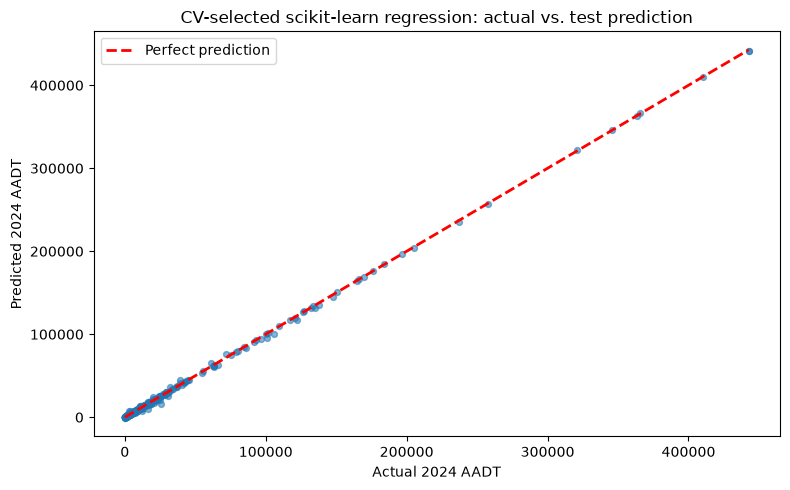

In [6]:
excluded = {
    "2024 AADT", "AADT_log", "AADT_2024", "Historical_AADT_2024",
    "Historical_growth_since_1988", "Location Description From",
    "Location Description To", "Merge_Key", "Location_Key",
    "Highway_Key", "index", "Year"
}
numeric_predictors = [
    column for column in study.select_dtypes(include=[np.number]).columns
    if column not in excluded
]

train_X_raw = train_set[numeric_predictors].replace([np.inf, -np.inf], np.nan)
test_X_raw = test_set[numeric_predictors].replace([np.inf, -np.inf], np.nan)
medians = train_X_raw.median()
usable_columns = medians.dropna().index
train_X = train_X_raw[usable_columns].fillna(medians[usable_columns]).fillna(0)
test_X = test_X_raw[usable_columns].fillna(medians[usable_columns]).fillna(0)
target_train = train_set["2024 AADT"]
target_test = test_set["2024 AADT"]

def model_metrics(model, X_train, X_test, y_train, y_test, predictor_count, model_rank):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)
    n = len(y_train)
    f_statistic = (train_r2 / model_rank) / ((1 - train_r2) / (n - model_rank - 1))
    return {
        "Predictors": predictor_count,
        "F-statistic": f_statistic,
        "R2 train": train_r2,
        "Adjusted R2 train": adjusted_r2(train_r2, n, model_rank),
        "R2 test": test_r2,
        "RMSE train": mean_squared_error(y_train, train_pred) ** 0.5,
        "RMSE test": mean_squared_error(y_test, test_pred) ** 0.5
    }

all_model = LinearRegression().fit(train_X, target_train)
all_metrics = model_metrics(all_model, train_X, test_X, target_train, target_test, train_X.shape[1], all_model.rank_)

k_candidates = sorted(set(min(k, train_X.shape[1]) for k in [1, 5, 10, 20, 40]))
selection_pipeline = Pipeline([
    ("select", SelectKBest(score_func=f_regression)),
    ("regression", LinearRegression())
])
search = GridSearchCV(
    selection_pipeline,
    param_grid={"select__k": k_candidates},
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=1
)
search.fit(train_X, target_train)
final_model = search.best_estimator_
selected_count = search.best_params_["select__k"]
final_regression = final_model.named_steps["regression"]
final_metrics = model_metrics(final_model, train_X, test_X, target_train, target_test, selected_count, final_regression.rank_)

model_comparison = pd.DataFrame(
    [all_metrics, final_metrics],
    index=["All predictors", "CV-selected model"]
).round(4)
display(model_comparison)

cv_results = pd.DataFrame({
    "Feature count": search.cv_results_["param_select__k"].astype(int),
    "Mean CV RMSE": -search.cv_results_["mean_test_score"]
}).sort_values("Feature count")
print("Cross-validation feature-count comparison:")
display(cv_results.round(2))

selected_mask = final_model.named_steps["select"].get_support()
selected_features = train_X.columns[selected_mask]
coefficients = pd.Series(
    final_regression.coef_,
    index=selected_features
).sort_values(key=np.abs, ascending=False)
print("Selected features:", len(selected_features))
display(coefficients.head(15).rename("Coefficient").to_frame().round(4))

final_test_pred = final_model.predict(test_X)
plt.figure(figsize=(8, 5))
plt.scatter(target_test, final_test_pred, alpha=0.55, s=18)
limits = [0, max(target_test.max(), final_test_pred.max())]
plt.plot(limits, limits, "r--", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual 2024 AADT")
plt.ylabel("Predicted 2024 AADT")
plt.title("CV-selected scikit-learn regression: actual vs. test prediction")
plt.legend()
plt.tight_layout()
plt.show()